# Lib

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC as svm
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
import missingno as msno
import xgboost as xgb
from sklearn.metrics import confusion_matrix  ,mean_absolute_error
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.impute import KNNImputer

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor
from sklearn.naive_bayes import GaussianNB

# Import Data

In [3]:
file_id = '1--BcvImIRK_UQhFY2Bwq8ez1QPHQvAnL'
url = f"https://drive.google.com/uc?export=download&id={file_id}"
data = pd.read_csv(url)
data.head()

,Date,Revenue,Ad Spend,Conversions,Service Type,Customer Type,Channel,Region
0,2024-02-15,1003.44,346.48,0,Standard,New,Referral,West
1,2024-01-24,1288.41,264.04,4,Premium,New,Google,West
2,2024-03-22,1201.38,389.72,10,Seasonal,Returning,Instagram,East
3,2024-03-21,742.60,275.16,9,Premium,Returning,Referral,North
4,2024-04-21,104.68,250.87,6,Premium,Returning,Google,South


# EDA

In [4]:
df=data.copy()
df

,Date,Revenue,Ad Spend,Conversions,Service Type,Customer Type,Channel,Region
0,2024-02-15,1003.44,346.48,0,Standard,New,Referral,West
1,2024-01-24,1288.41,264.04,4,Premium,New,Google,West
2,2024-03-22,1201.38,389.72,10,Seasonal,Returning,Instagram,East
3,2024-03-21,742.60,275.16,9,Premium,Returning,Referral,North
4,2024-04-21,104.68,250.87,6,Premium,Returning,Google,South
...,...,...,...,...,...,...,...,...
1995,2024-01-02,193.09,435.88,3,Standard,New,Email,East
1996,2024-02-07,1050.22,457.79,5,Premium,Returning,Google,South
1997,2024-04-28,858.74,289.00,5,Premium,Returning,Instagram,North
1998,2024-02-21,788.98,127.55,2,Standard,Returning,Instagram,North


In [5]:
df.isna().sum()

,0
Date,0
Revenue,0
Ad Spend,0
Conversions,0
Service Type,0
Customer Type,0
Channel,0
Region,0


In [6]:
df.count()

,0
Date,2000
Revenue,2000
Ad Spend,2000
Conversions,2000
Service Type,2000
Customer Type,2000
Channel,2000
Region,2000


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df['Conversions'].unique()

array([ 0,  4, 10,  9,  6,  2,  3,  8,  5,  7,  1])

In [11]:
df['Service Type'].unique()

array(['Standard', 'Premium', 'Seasonal'], dtype=object)

In [12]:
df['Customer Type'].unique()

array(['New', 'Returning'], dtype=object)

In [13]:
df['Channel'].unique()

array(['Referral', 'Google', 'Instagram', 'Email'], dtype=object)

In [14]:
df['Region'].unique()

array(['West', 'East', 'North', 'South'], dtype=object)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           2000 non-null   object 
 1   Revenue        2000 non-null   float64
 2   Ad Spend       2000 non-null   float64
 3   Conversions    2000 non-null   int64  
 4   Service Type   2000 non-null   object 
 5   Customer Type  2000 non-null   object 
 6   Channel        2000 non-null   object 
 7   Region         2000 non-null   object 
dtypes: float64(2), int64(1), object(5)
memory usage: 125.1+ KB


# Visualization & Analysis

In [16]:
# Prepare data
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.to_period('M').astype(str)

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

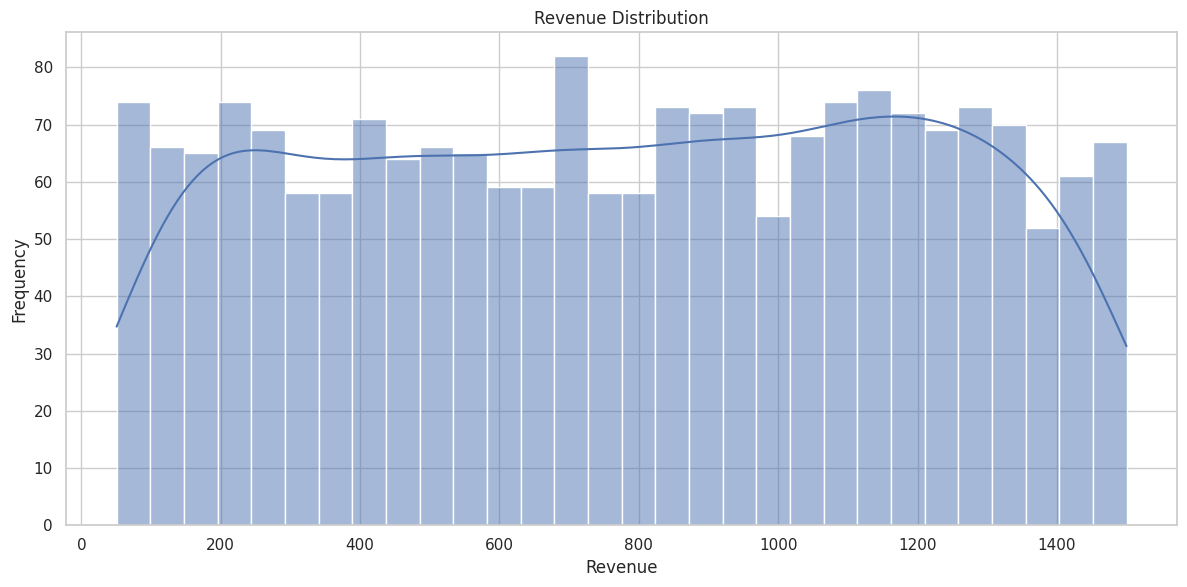

In [17]:
# ==========================================
# 1. Revenue Distribution
# ==========================================
plt.figure(figsize=(12, 6))
sns.histplot(data=df, x='Revenue', kde=True, bins=30)
plt.title('Revenue Distribution')
plt.xlabel('Revenue')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

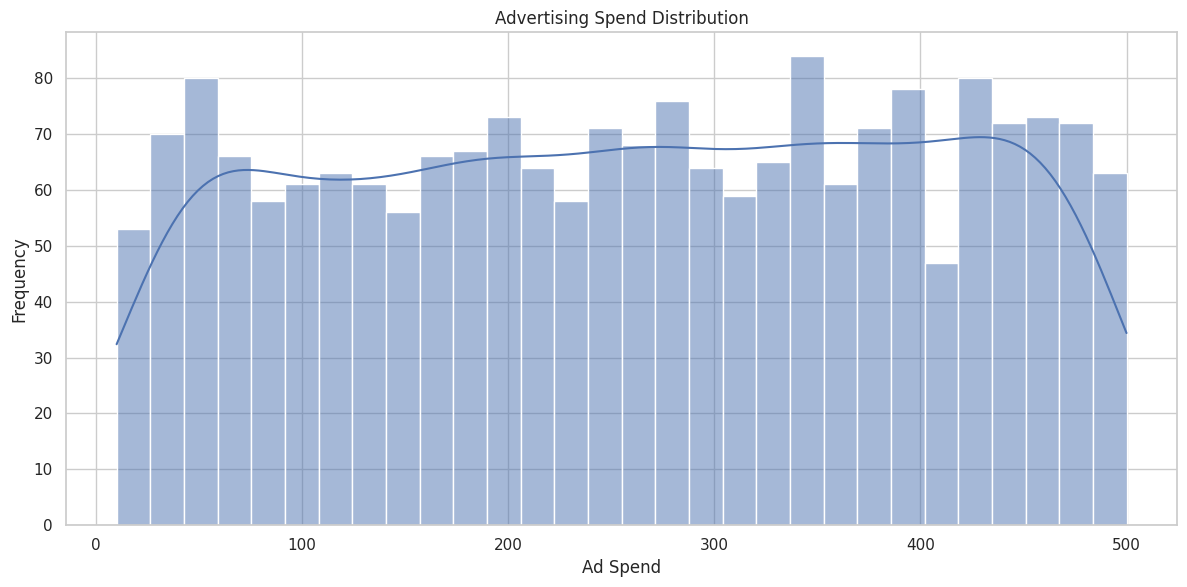

In [18]:
# ==========================================
# 2. Advertising Spend Distribution
# ==========================================
plt.figure(figsize=(12, 6))
sns.histplot(data=df, x='Ad Spend', kde=True, bins=30)
plt.title('Advertising Spend Distribution')
plt.xlabel('Ad Spend')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

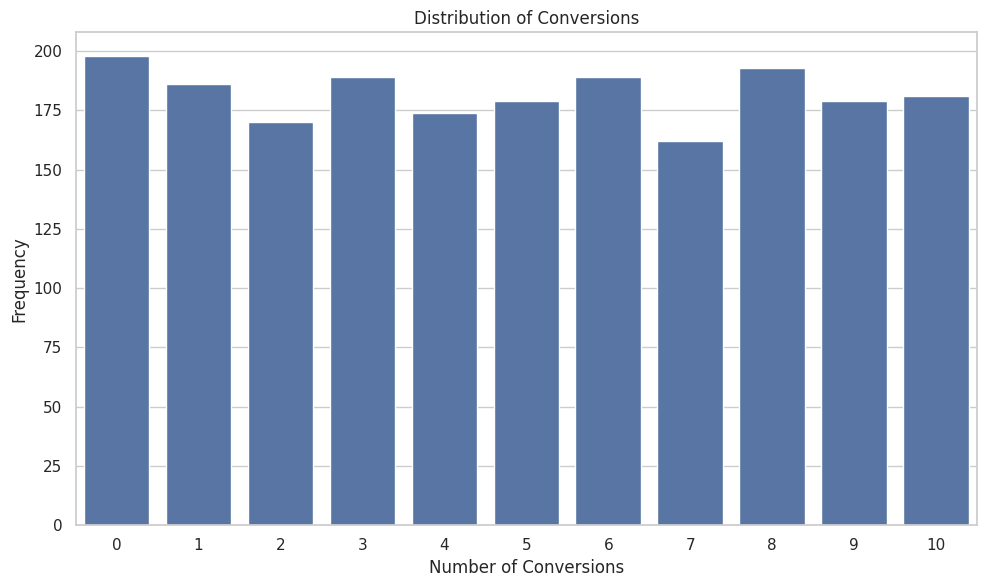

In [19]:
# ==========================================
# 3. Conversions Distribution
# ==========================================
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Conversions')
plt.title('Distribution of Conversions')
plt.xlabel('Number of Conversions')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

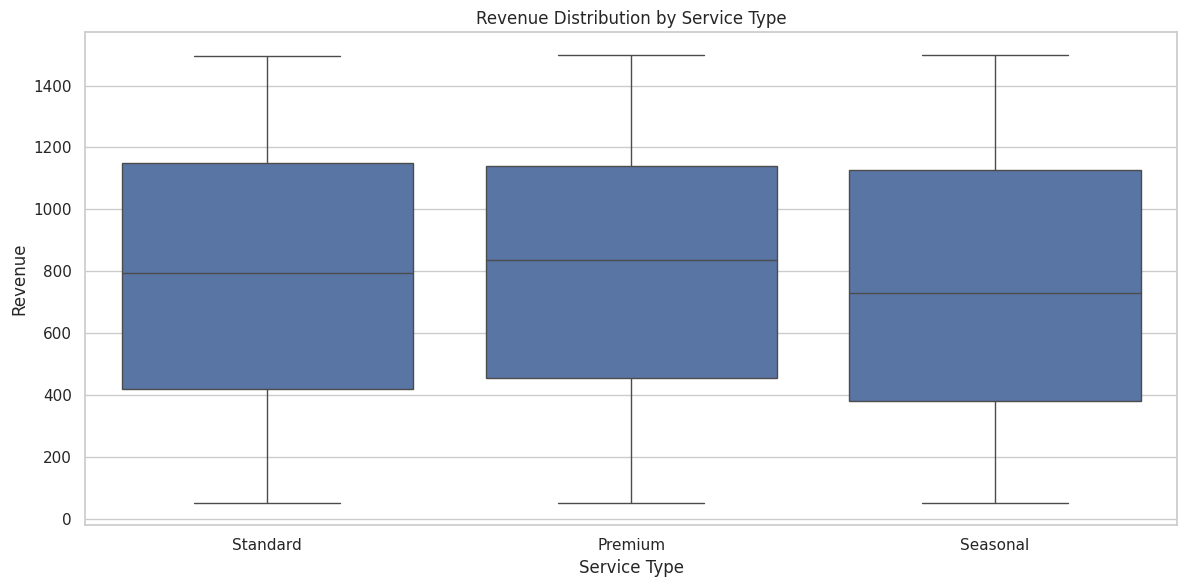

In [20]:
# ==========================================
# 4. Revenue by Service Type
# ==========================================
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='Service Type', y='Revenue')
plt.title('Revenue Distribution by Service Type')
plt.xlabel('Service Type')
plt.ylabel('Revenue')
plt.tight_layout()
plt.show()

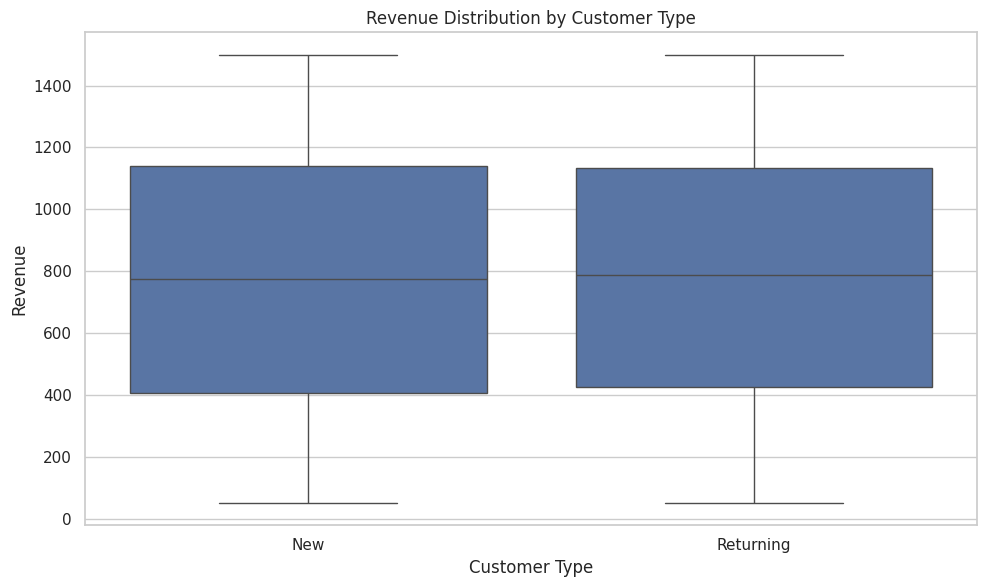

In [21]:
# ==========================================
# 5. Revenue by Customer Type
# ==========================================
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Customer Type', y='Revenue')
plt.title('Revenue Distribution by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Revenue')
plt.tight_layout()
plt.show()


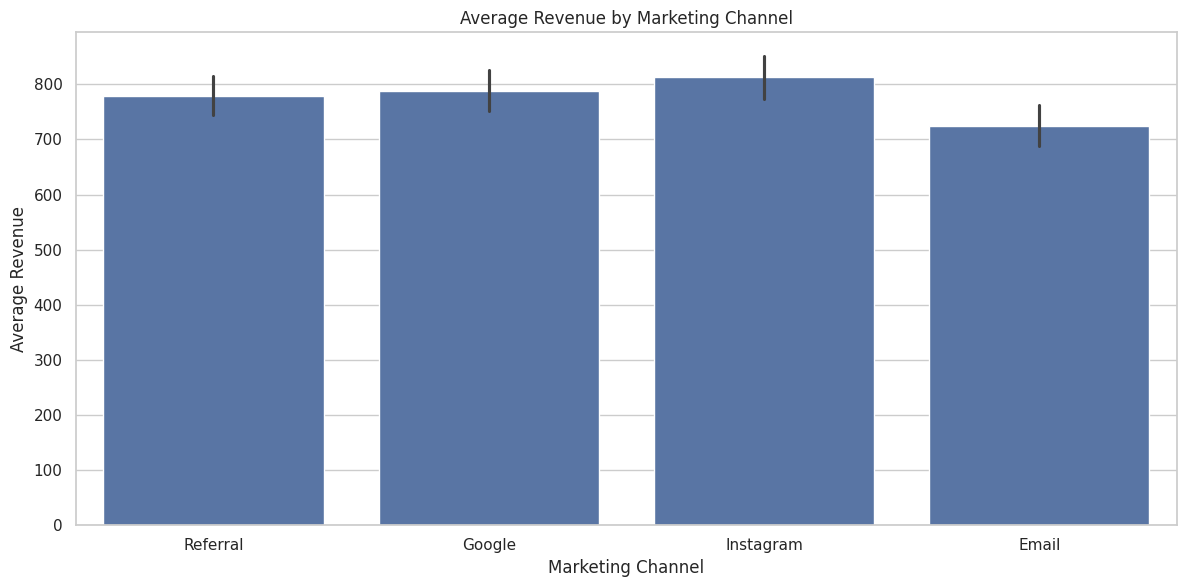

In [22]:
# ==========================================
# 6. Average Revenue by Marketing Channel
# ==========================================
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x='Channel', y='Revenue', estimator='mean')
plt.title('Average Revenue by Marketing Channel')
plt.xlabel('Marketing Channel')
plt.ylabel('Average Revenue')
plt.tight_layout()
plt.show()


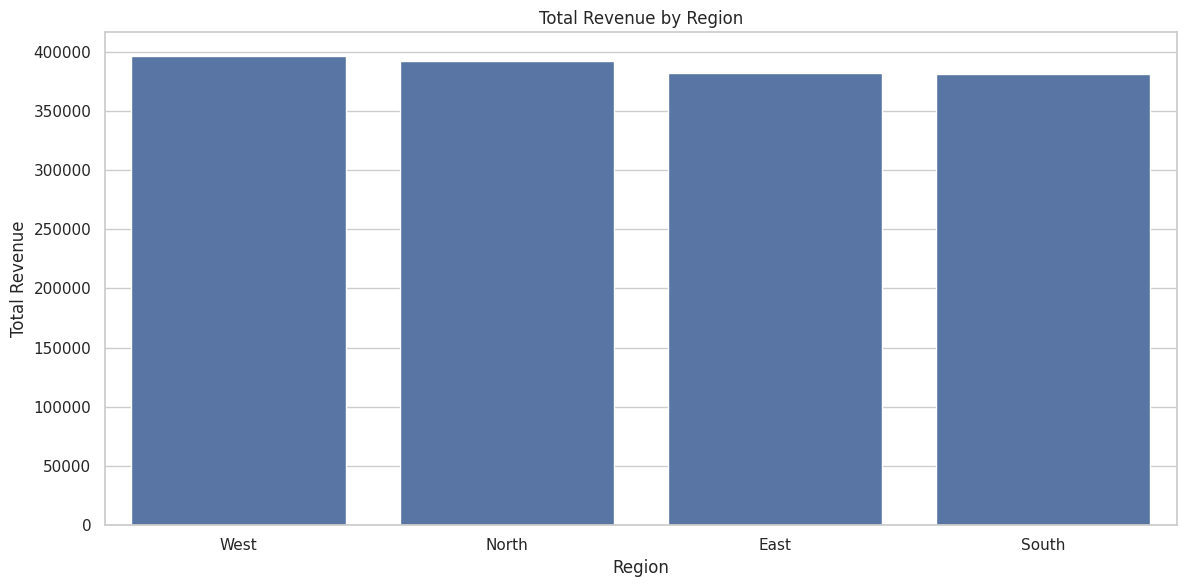

In [23]:
# ==========================================
# 7. Total Revenue by Region
# ==========================================
region_revenue = df.groupby('Region')['Revenue'].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=region_revenue.index, y=region_revenue.values)
plt.title('Total Revenue by Region')
plt.xlabel('Region')
plt.ylabel('Total Revenue')
plt.tight_layout()
plt.show()

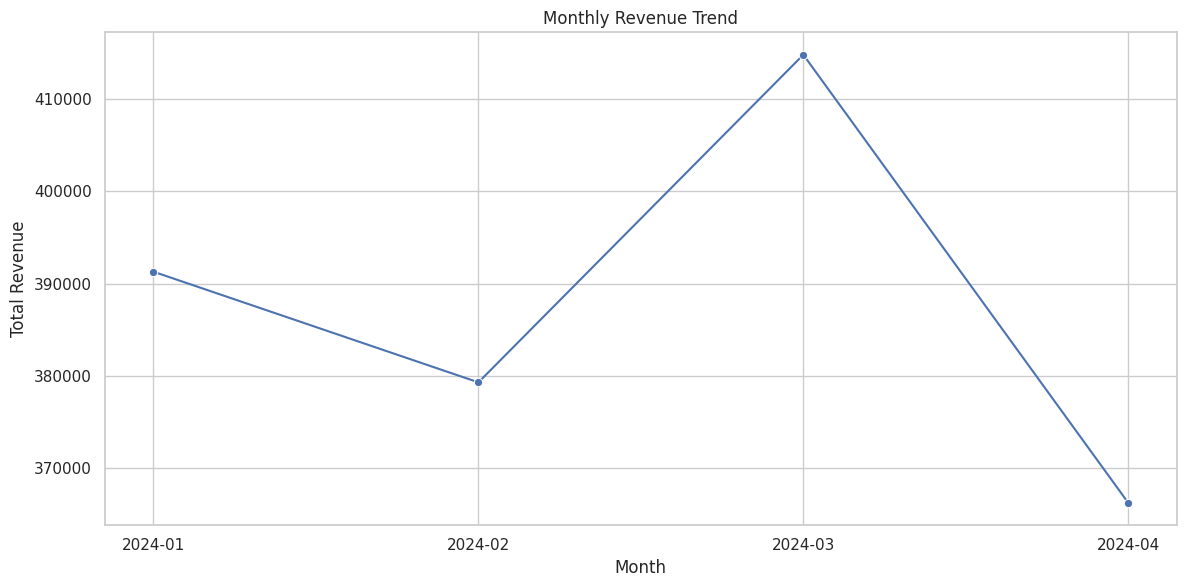

In [24]:
# ==========================================
# 8. Monthly Revenue Trend
# ==========================================
monthly = df.groupby('Month', as_index=False)['Revenue'].sum()

plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly, x='Month', y='Revenue', marker='o')
plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.tight_layout()
plt.show()


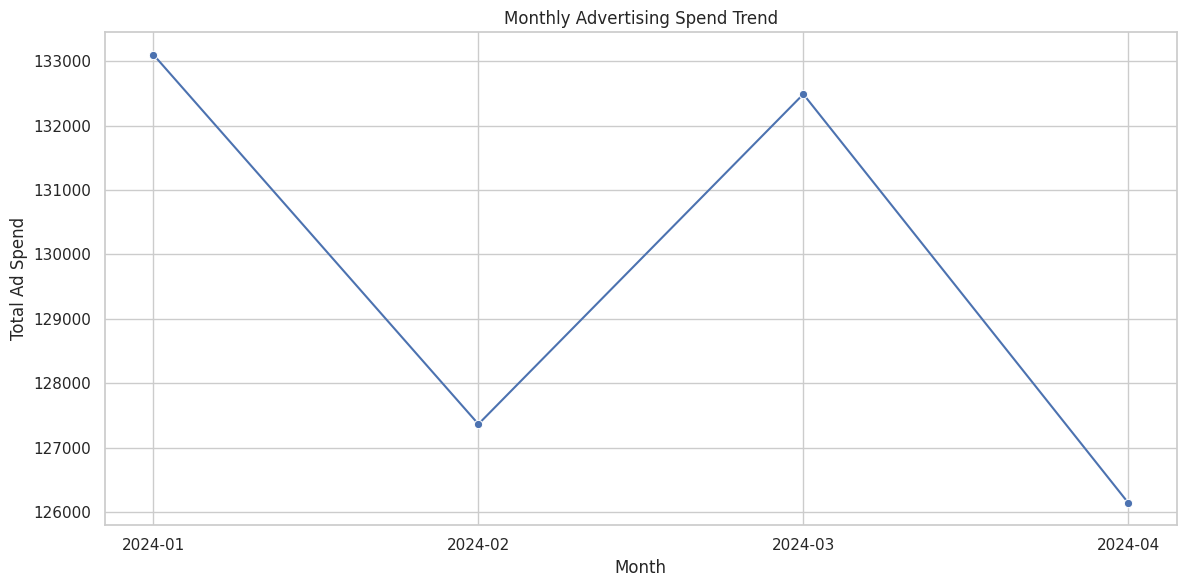

In [25]:
# ==========================================
# 9. Monthly Advertising Spend
# ==========================================
monthly_ad = df.groupby('Month', as_index=False)['Ad Spend'].sum()

plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_ad, x='Month', y='Ad Spend', marker='o')
plt.title('Monthly Advertising Spend Trend')
plt.xlabel('Month')
plt.ylabel('Total Ad Spend')
plt.tight_layout()
plt.show()


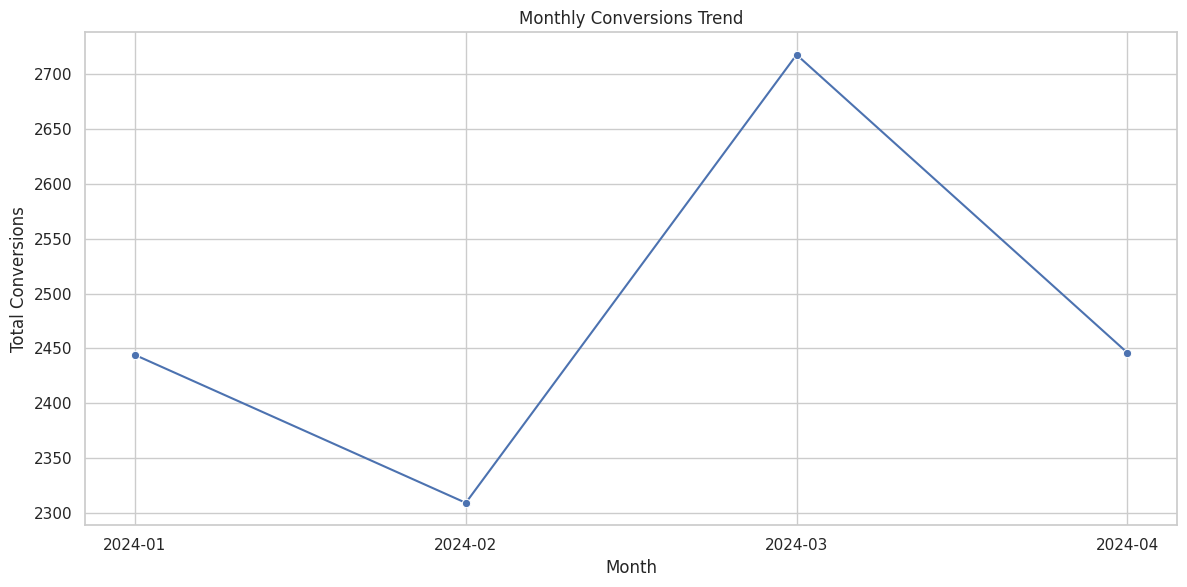

In [26]:
# ==========================================
# 10. Monthly Conversions Trend
# ==========================================
monthly_conv = df.groupby('Month', as_index=False)['Conversions'].sum()

plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_conv, x='Month', y='Conversions', marker='o')
plt.title('Monthly Conversions Trend')
plt.xlabel('Month')
plt.ylabel('Total Conversions')
plt.tight_layout()
plt.show()

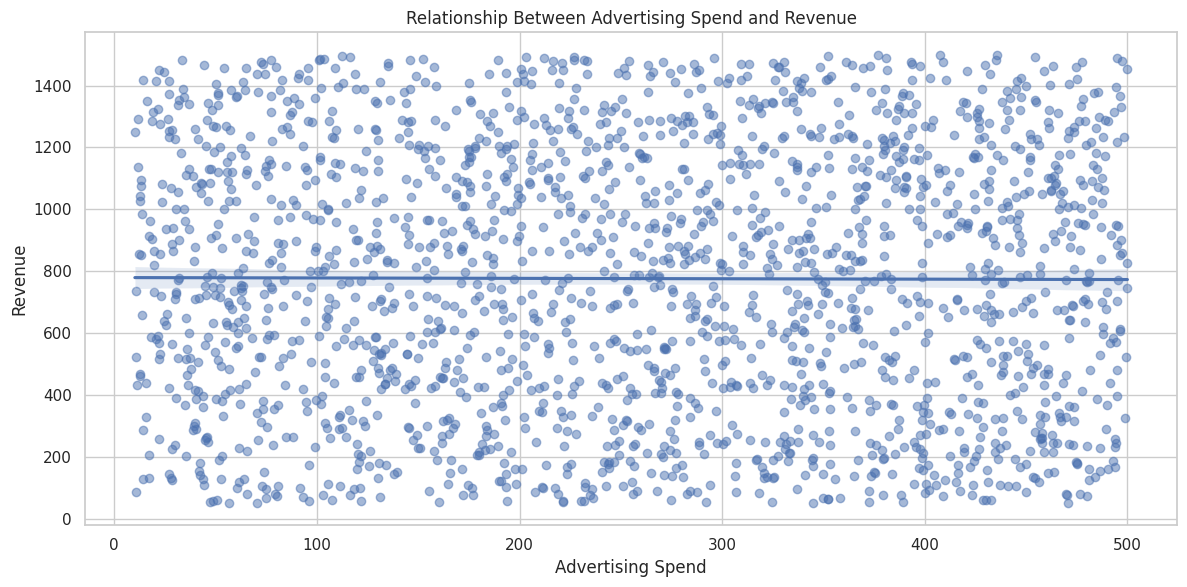

In [27]:
# ==========================================
# 11. Advertising Spend vs Revenue
# ==========================================
plt.figure(figsize=(12, 6))
sns.regplot(data=df, x='Ad Spend', y='Revenue',
            scatter_kws={'alpha': 0.5})
plt.title('Relationship Between Advertising Spend and Revenue')
plt.xlabel('Advertising Spend')
plt.ylabel('Revenue')
plt.tight_layout()
plt.show()

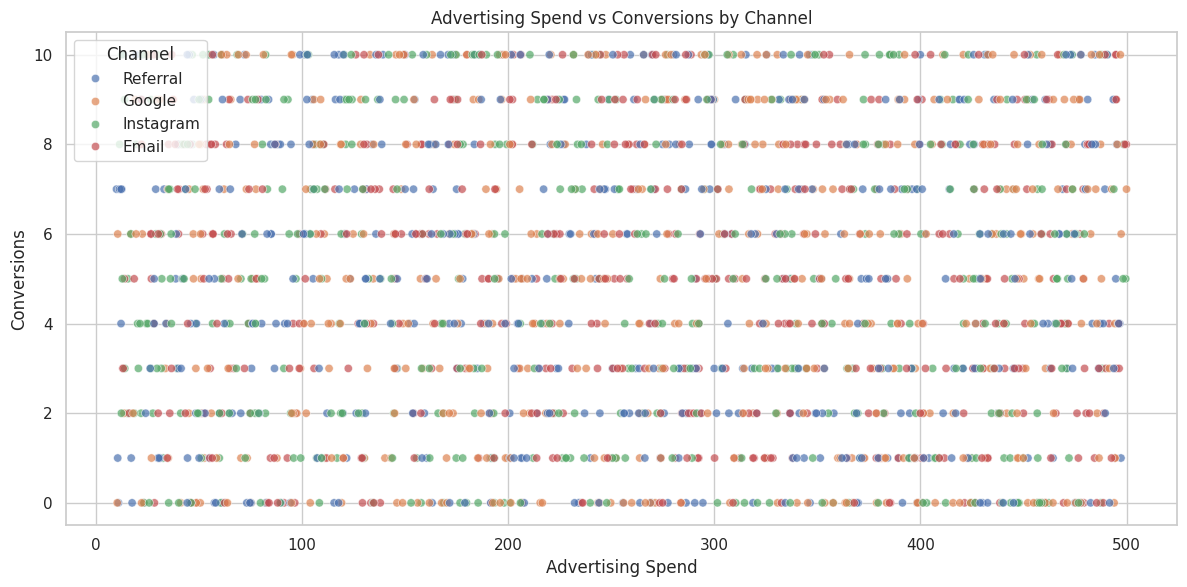

In [28]:
# ==========================================
# 12. Advertising Spend vs Conversions
# ==========================================
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x='Ad Spend', y='Conversions',
                hue='Channel', alpha=0.7)
plt.title('Advertising Spend vs Conversions by Channel')
plt.xlabel('Advertising Spend')
plt.ylabel('Conversions')
plt.tight_layout()
plt.show()

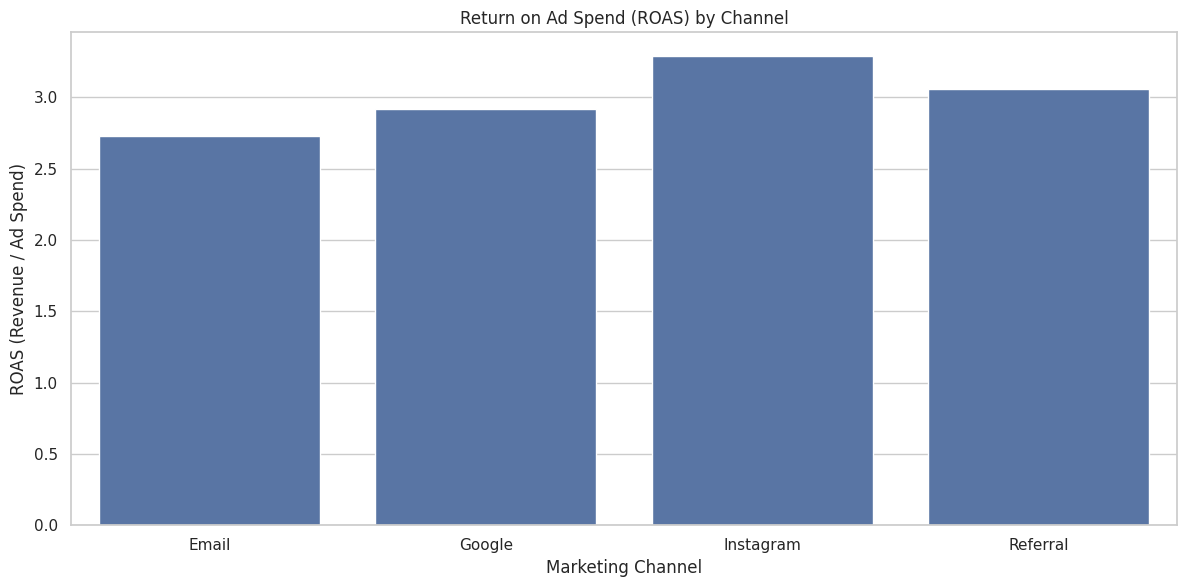

In [29]:
# ==========================================
# 13. Return on Ad Spend (ROAS) by Channel
# ==========================================
channel_performance = df.groupby('Channel').agg(
    Total_Revenue=('Revenue', 'sum'),
    Total_Ad_Spend=('Ad Spend', 'sum')
)

channel_performance['ROAS'] = (
    channel_performance['Total_Revenue'] /
    channel_performance['Total_Ad_Spend']
)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=channel_performance.index,
    y=channel_performance['ROAS']
)
plt.title('Return on Ad Spend (ROAS) by Channel')
plt.xlabel('Marketing Channel')
plt.ylabel('ROAS (Revenue / Ad Spend)')
plt.tight_layout()
plt.show()

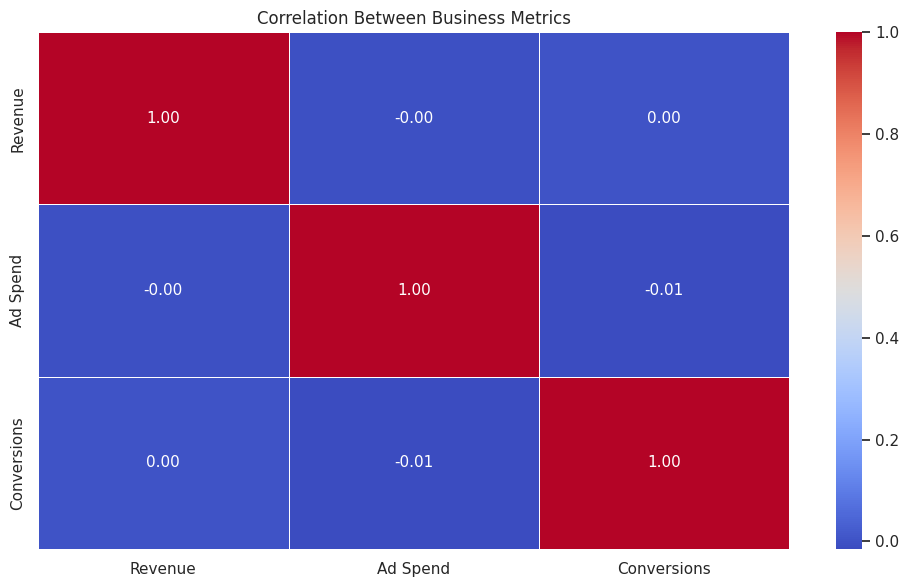

In [30]:
# ==========================================
# 14. Correlation Heatmap
# ==========================================
numeric_df = df[['Revenue', 'Ad Spend', 'Conversions']]

plt.figure(figsize=(10, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)
plt.title('Correlation Between Business Metrics')
plt.tight_layout()
plt.show()

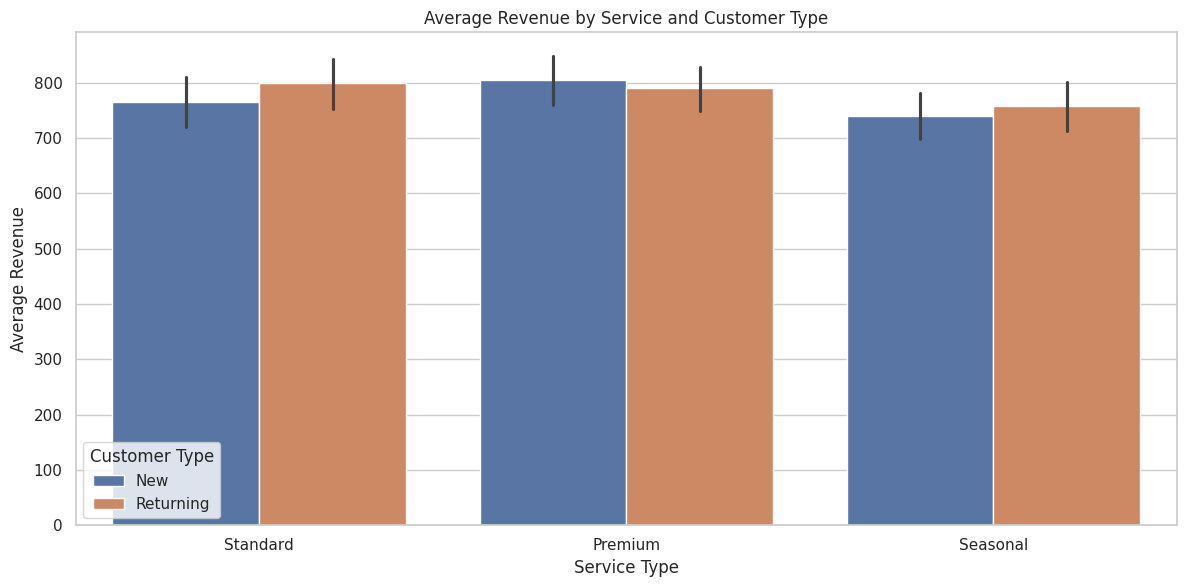

In [31]:
# ==========================================
# 15. Revenue by Service Type and Customer Type
# ==========================================
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df,
    x='Service Type',
    y='Revenue',
    hue='Customer Type',
    estimator='mean'
)
plt.title('Average Revenue by Service and Customer Type')
plt.xlabel('Service Type')
plt.ylabel('Average Revenue')
plt.legend(title='Customer Type')
plt.tight_layout()
plt.show()

# Data Cleaning

In [33]:

# 1. Remove duplicate records
df = df.drop_duplicates().copy()

# 2. Convert Date to datetime
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# 3. Clean categorical columns
categorical_cols = [
    'Service Type',
    'Customer Type',
    'Channel',
    'Region'
]

for col in categorical_cols:
    df[col] = df[col].astype('string').str.strip()

# 4. Convert numerical columns
numeric_cols = ['Revenue', 'Ad Spend', 'Conversions']

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 5. Check missing values
print("Missing Values:")
print(df.isnull().sum())

# 6. Check invalid numerical values
print("\nNegative Values:")
print((df[numeric_cols] < 0).sum())

# 7. Check zero conversions
print("\nZero Conversions:")
print((df['Conversions'] == 0).sum())

# 8. Check categorical values
for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())

# 9. Extract time features
df['Month'] = df['Date'].dt.month_name()
df['Year'] = df['Date'].dt.year

# 10. Check outliers using IQR
for col in ['Revenue', 'Ad Spend']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]

    print(f"\n{col} Outliers: {len(outliers)}")

# Final dataset
df = df.dropna(subset=[
    'Date', 'Revenue', 'Ad Spend', 'Conversions'
])

print("\nFinal Dataset Shape:", df.shape)
print(df.head())


Missing Values:
Date             0
Revenue          0
Ad Spend         0
Conversions      0
Service Type     0
Customer Type    0
Channel          0
Region           0
Month            0
dtype: int64

Negative Values:
Revenue        0
Ad Spend       0
Conversions    0
dtype: int64

Zero Conversions:
198

Service Type:
Service Type
Seasonal    684
Standard    663
Premium     653
Name: count, dtype: Int64

Customer Type:
Customer Type
Returning    1019
New           981
Name: count, dtype: Int64

Channel:
Channel
Email        507
Google       503
Referral     499
Instagram    491
Name: count, dtype: Int64

Region:
Region
West     516
North    502
East     492
South    490
Name: count, dtype: Int64

Revenue Outliers: 0

Ad Spend Outliers: 0

Final Dataset Shape: (2000, 10)
        Date  Revenue  Ad Spend  Conversions Service Type Customer Type  \
0 2024-02-15  1003.44    346.48            0     Standard           New   
1 2024-01-24  1288.41    264.04            4      Premium           N

# Analysis

In [34]:

# ==========================================
# PHASE 3: SALES ANALYSIS
# ==========================================

# 1. General Sales KPIs
total_revenue = df['Revenue'].sum()
total_ad_spend = df['Ad Spend'].sum()
total_conversions = df['Conversions'].sum()

average_revenue = df['Revenue'].mean()
average_ad_spend = df['Ad Spend'].mean()

overall_roas = total_revenue / total_ad_spend

print("Total Revenue:", total_revenue)
print("Total Ad Spend:", total_ad_spend)
print("Total Conversions:", total_conversions)
print("Average Revenue:", average_revenue)
print("Overall ROAS:", overall_roas)


# 2. Revenue by Service Type
service_analysis = df.groupby('Service Type').agg(
    Total_Revenue=('Revenue', 'sum'),
    Average_Revenue=('Revenue', 'mean'),
    Total_Conversions=('Conversions', 'sum')
).sort_values('Total_Revenue', ascending=False)

print("\nRevenue by Service:")
print(service_analysis)


# 3. Revenue by Customer Type
customer_analysis = df.groupby('Customer Type').agg(
    Total_Revenue=('Revenue', 'sum'),
    Average_Revenue=('Revenue', 'mean'),
    Total_Conversions=('Conversions', 'sum')
)

print("\nCustomer Analysis:")
print(customer_analysis)


# 4. Revenue by Region
region_analysis = df.groupby('Region').agg(
    Total_Revenue=('Revenue', 'sum'),
    Average_Revenue=('Revenue', 'mean'),
    Total_Conversions=('Conversions', 'sum')
).sort_values('Total_Revenue', ascending=False)

print("\nRegional Analysis:")
print(region_analysis)


# 5. Monthly Sales Analysis
monthly_sales = df.groupby(
    df['Date'].dt.to_period('M')
).agg(
    Revenue=('Revenue', 'sum'),
    Ad_Spend=('Ad Spend', 'sum'),
    Conversions=('Conversions', 'sum')
)

print("\nMonthly Sales:")
print(monthly_sales)


# 6. Best Selling Channel
channel_sales = df.groupby('Channel').agg(
    Revenue=('Revenue', 'sum'),
    Ad_Spend=('Ad Spend', 'sum'),
    Conversions=('Conversions', 'sum')
)

channel_sales['ROAS'] = (
    channel_sales['Revenue'] /
    channel_sales['Ad_Spend']
)

print("\nChannel Performance:")
print(channel_sales.sort_values('Revenue', ascending=False))


Total Revenue: 1551612.25
Total Ad Spend: 519098.07
Total Conversions: 9917
Average Revenue: 775.806125
Overall ROAS: 2.9890541685119345

Revenue by Service:
              Total_Revenue  Average_Revenue  Total_Conversions
Service Type                                                   
Premium           520943.84       797.770046               3207
Standard          517912.48       781.165128               3257
Seasonal          512755.93       749.643173               3453

Customer Analysis:
               Total_Revenue  Average_Revenue  Total_Conversions
Customer Type                                                   
New                755531.24       770.164363               4725
Returning          796081.01       781.237498               5192

Regional Analysis:
        Total_Revenue  Average_Revenue  Total_Conversions
Region                                                   
West        396377.41       768.173275               2633
North       391839.93       780.557629          

# Conversion Performance Analysis

In [35]:

# ==========================================
# PHASE 4 ALTERNATIVE:
# CONVERSION PERFORMANCE ANALYSIS
# ==========================================

# 1. Average conversions by channel
conversion_channel = df.groupby('Channel').agg(
    Total_Conversions=('Conversions', 'sum'),
    Average_Conversions=('Conversions', 'mean'),
    Revenue=('Revenue', 'sum')
).sort_values('Total_Conversions', ascending=False)

print(conversion_channel)


# 2. Conversion performance by customer type
customer_conversion = df.groupby('Customer Type').agg(
    Total_Conversions=('Conversions', 'sum'),
    Average_Conversions=('Conversions', 'mean')
)

print(customer_conversion)


# 3. Zero conversion records
zero_conversion = df[df['Conversions'] == 0]

print("Zero Conversion Records:", len(zero_conversion))
print("Revenue in Zero Conversion Records:",
      zero_conversion['Revenue'].sum())

# Note:
# Verify the business definition of Conversion
# before interpreting these records.


           Total_Conversions  Average_Conversions    Revenue
Channel                                                     
Google                  2519             5.007952  396244.35
Referral                2507             5.024048  389098.95
Email                   2483             4.897436  367233.76
Instagram               2408             4.904277  399035.19
               Total_Conversions  Average_Conversions
Customer Type                                        
New                         4725             4.816514
Returning                   5192             5.095191
Zero Conversion Records: 198
Revenue in Zero Conversion Records: 146628.41


# Marketing Analysis

In [36]:

# ==========================================
# PHASE 5: MARKETING ANALYSIS
# ==========================================

# 1. Marketing Channel Performance
marketing = df.groupby('Channel').agg(
    Total_Revenue=('Revenue', 'sum'),
    Total_Ad_Spend=('Ad Spend', 'sum'),
    Total_Conversions=('Conversions', 'sum')
)

# Calculate ROAS
marketing['ROAS'] = (
    marketing['Total_Revenue'] /
    marketing['Total_Ad_Spend']
)

# Calculate revenue per conversion
marketing['Revenue_Per_Conversion'] = (
    marketing['Total_Revenue'] /
    marketing['Total_Conversions'].replace(0, np.nan)
)

# Sort by ROAS
marketing = marketing.sort_values(
    'ROAS', ascending=False
)

print(marketing)


# 2. Revenue Share by Channel
marketing['Revenue_Share_%'] = (
    marketing['Total_Revenue'] /
    marketing['Total_Revenue'].sum()
) * 100

print("\nRevenue Share:")
print(marketing['Revenue_Share_%'])


# 3. Advertising Spend Share
marketing['Ad_Spend_Share_%'] = (
    marketing['Total_Ad_Spend'] /
    marketing['Total_Ad_Spend'].sum()
) * 100

print("\nAdvertising Spend Share:")
print(marketing['Ad_Spend_Share_%'])


# 4. Marketing Efficiency
marketing['Revenue_to_Ad_Spend_Difference'] = (
    marketing['Total_Revenue'] -
    marketing['Total_Ad_Spend']
)

print("\nMarketing Efficiency:")
print(marketing)


           Total_Revenue  Total_Ad_Spend  Total_Conversions      ROAS  \
Channel                                                                 
Instagram      399035.19       121289.60               2408  3.289937   
Referral       389098.95       127210.27               2507  3.058707   
Google         396244.35       135918.35               2519  2.915312   
Email          367233.76       134679.85               2483  2.726716   

           Revenue_Per_Conversion  
Channel                            
Instagram              165.712288  
Referral               155.205006  
Google                 157.302243  
Email                  147.899219  

Revenue Share:
Channel
Instagram    25.717456
Referral     25.077074
Google       25.537588
Email        23.667882
Name: Revenue_Share_%, dtype: float64

Advertising Spend Share:
Channel
Instagram    23.365450
Referral     24.506019
Google       26.183559
Email        25.944972
Name: Ad_Spend_Share_%, dtype: float64

Marketing Efficiency:
   

# New Section

In [39]:

# ==========================================
# ADVANCED BUSINESS ANALYSIS
# ==========================================

# 1. Revenue Contribution by Service
service_contribution = (
    df.groupby('Service Type')['Revenue'].sum()
    / df['Revenue'].sum()
) * 100

print("Service Revenue Contribution:")
print(service_contribution)


# 2. Revenue Contribution by Customer
customer_contribution = (
    df.groupby('Customer Type')['Revenue'].sum()
    / df['Revenue'].sum()
) * 100

print("\nCustomer Revenue Contribution:")
print(customer_contribution)


# 3. Service vs Marketing Channel
service_channel = df.pivot_table(
    index='Service Type',
    columns='Channel',
    values='Revenue',
    aggfunc='sum'
)

print("\nService vs Channel:")
print(service_channel)


# 4. Region vs Marketing Channel
region_channel = df.pivot_table(
    index='Region',
    columns='Channel',
    values='Revenue',
    aggfunc='sum'
)

print("\nRegion vs Channel:")
print(region_channel)


# 5. Monthly Revenue Growth
monthly_revenue = df.groupby(
    df['Date'].dt.to_period('M')
)['Revenue'].sum()

monthly_growth = monthly_revenue.pct_change() * 100

print("\nMonthly Revenue Growth:")
print(monthly_growth)


# 6. Revenue per Conversion
df['Revenue_Per_Conversion'] = np.where(
    df['Conversions'] > 0,
    df['Revenue'] / df['Conversions'],
    np.nan
)

print("\nRevenue per Conversion:")
print(df['Revenue_Per_Conversion'].describe())


# 7. Channel Efficiency
channel_efficiency = df.groupby('Channel').agg(
    Revenue=('Revenue', 'sum'),
    Ad_Spend=('Ad Spend', 'sum'),
    Conversions=('Conversions', 'sum')
)

channel_efficiency['ROAS'] = (
    channel_efficiency['Revenue'] /
    channel_efficiency['Ad_Spend']
)

channel_efficiency['Conversion_per_100_Ad_Spend'] = (
    channel_efficiency['Conversions'] /
    channel_efficiency['Ad_Spend'] * 100
)

print("\nChannel Efficiency:")
print(channel_efficiency)


Service Revenue Contribution:
Service Type
Premium     33.574357
Seasonal    33.046654
Standard    33.378989
Name: Revenue, dtype: float64

Customer Revenue Contribution:
Customer Type
New          48.693302
Returning    51.306698
Name: Revenue, dtype: float64

Service vs Channel:
Channel           Email     Google  Instagram   Referral
Service Type                                            
Premium       129742.82  123521.20  128254.30  139425.52
Seasonal      110044.73  138985.55  139263.69  124461.96
Standard      127446.21  133737.60  131517.20  125211.47

Region vs Channel:
Channel      Email     Google  Instagram   Referral
Region                                             
East      78215.61   88470.01  116336.78   99029.55
North     84851.95  104355.33   94917.70  107714.95
South    105321.58  100219.58   98486.91   77314.89
West      98844.62  103199.43   89293.80  105039.56

Monthly Revenue Growth:
Date
2024-01          NaN
2024-02    -3.060490
2024-03     9.349152
2024-04 

# Recommendation Engine

In [40]:

def recommendation_engine(df):

    data = df.copy()
    recommendations = []

    # Ensure correct data types
    data["Date"] = pd.to_datetime(data["Date"])
    data["Revenue"] = pd.to_numeric(data["Revenue"])
    data["Ad Spend"] = pd.to_numeric(data["Ad Spend"])
    data["Conversions"] = pd.to_numeric(data["Conversions"])

    # Overall KPIs
    total_revenue = data["Revenue"].sum()
    total_spend = data["Ad Spend"].sum()
    total_conversions = data["Conversions"].sum()

    overall_roas = (
        total_revenue / total_spend if total_spend > 0 else 0
    )

    # Helper function
    def add_recommendation(priority, category, finding, action, evidence):
        recommendations.append({
            "Priority": priority,
            "Category": category,
            "Finding": finding,
            "Recommendation": action,
            "Evidence": evidence
        })

    # 1. Marketing Channel Recommendations
    channel_stats = data.groupby("Channel").agg(
        Revenue=("Revenue", "sum"),
        Ad_Spend=("Ad Spend", "sum"),
        Conversions=("Conversions", "sum"),
        Records=("Revenue", "size")
    )

    channel_stats["ROAS"] = np.where(
        channel_stats["Ad_Spend"] > 0,
        channel_stats["Revenue"] / channel_stats["Ad_Spend"],
        np.nan
    )

    for channel, row in channel_stats.iterrows():

        if pd.isna(row["ROAS"]):
            continue

        if row["ROAS"] >= overall_roas * 1.10:
            add_recommendation(
                "High",
                "Marketing",
                f"{channel} is an above-average channel.",
                f"Consider gradually increasing {channel} budget "
                "through controlled budget tests.",
                f"ROAS: {row['ROAS']:.2f} vs "
                f"Overall ROAS: {overall_roas:.2f}"
            )

        elif row["ROAS"] < overall_roas * 0.80:
            add_recommendation(
                "High",
                "Marketing",
                f"{channel} is performing below average.",
                f"Review {channel} campaigns, targeting, "
                "and advertising costs before allocating more budget.",
                f"ROAS: {row['ROAS']:.2f} vs "
                f"Overall ROAS: {overall_roas:.2f}"
            )

    # 2. Service Performance
    service_stats = data.groupby("Service Type").agg(
        Revenue=("Revenue", "sum"),
        Ad_Spend=("Ad Spend", "sum"),
        Conversions=("Conversions", "sum")
    )

    service_stats["ROAS"] = np.where(
        service_stats["Ad_Spend"] > 0,
        service_stats["Revenue"] / service_stats["Ad_Spend"],
        np.nan
    )

    for service, row in service_stats.iterrows():

        if pd.notna(row["ROAS"]) and row["ROAS"] >= overall_roas * 1.10:
            add_recommendation(
                "Medium",
                "Service",
                f"{service} has strong advertising efficiency.",
                f"Prioritize testing additional campaigns for {service}.",
                f"ROAS: {row['ROAS']:.2f}"
            )

        elif pd.notna(row["ROAS"]) and row["ROAS"] < overall_roas * 0.80:
            add_recommendation(
                "Medium",
                "Service",
                f"{service} has relatively low advertising efficiency.",
                f"Review pricing, promotion, and campaign targeting "
                f"for {service}.",
                f"ROAS: {row['ROAS']:.2f}"
            )

    # 3. Customer Retention
    customer_revenue = data.groupby("Customer Type")["Revenue"].sum()

    returning_revenue = customer_revenue.get("Returning", 0)
    returning_share = (
        returning_revenue / total_revenue * 100
        if total_revenue > 0 else 0
    )

    if returning_share < 50:
        add_recommendation(
            "High",
            "Customer Retention",
            "Returning customers contribute less than half of revenue.",
            "Introduce loyalty programs, repeat-purchase offers, "
            "and customer retention campaigns.",
            f"Returning customer revenue share: {returning_share:.2f}%"
        )
    else:
        add_recommendation(
            "Medium",
            "Customer Retention",
            "Returning customers represent a strong revenue contribution.",
            "Maintain customer loyalty initiatives and test "
            "personalized offers to improve repeat purchases.",
            f"Returning customer revenue share: {returning_share:.2f}%"
        )

    # 4. Monthly Revenue Trend
    monthly_revenue = (
        data.set_index("Date")
        .resample("ME")["Revenue"]
        .sum()
    )

    if len(monthly_revenue) >= 2:

        current = monthly_revenue.iloc[-1]
        previous = monthly_revenue.iloc[-2]

        growth = (
            (current - previous) / previous * 100
            if previous > 0 else np.nan
        )

        if pd.notna(growth) and growth < -5:
            add_recommendation(
                "High",
                "Revenue Trend",
                "Revenue declined significantly in the latest month.",
                "Investigate channel, service, and regional "
                "performance to identify the main causes.",
                f"Monthly revenue change: {growth:.2f}%"
            )

        elif pd.notna(growth) and growth > 5:
            add_recommendation(
                "Low",
                "Revenue Trend",
                "Revenue increased in the latest month.",
                "Identify the segments driving growth and test "
                "whether their performance can be sustained.",
                f"Monthly revenue change: +{growth:.2f}%"
            )

    # 5. Regional Performance
    region_stats = data.groupby("Region").agg(
        Revenue=("Revenue", "sum"),
        Ad_Spend=("Ad Spend", "sum")
    )

    region_stats["ROAS"] = np.where(
        region_stats["Ad_Spend"] > 0,
        region_stats["Revenue"] / region_stats["Ad_Spend"],
        np.nan
    )

    valid_regions = region_stats.dropna(subset=["ROAS"])

    if len(valid_regions) >= 2:

        best_region = valid_regions["ROAS"].idxmax()
        worst_region = valid_regions["ROAS"].idxmin()

        add_recommendation(
            "Medium",
            "Regional Performance",
            f"{best_region} has the highest regional ROAS.",
            f"Study successful campaigns in {best_region} "
            f"and test transferable strategies in {worst_region}.",
            f"Best: {best_region} ({valid_regions.loc[best_region, 'ROAS']:.2f}), "
            f"Lowest: {worst_region} "
            f"({valid_regions.loc[worst_region, 'ROAS']:.2f})"
        )

    # 6. Data Quality Alert
    zero_conversion_revenue = data.loc[
        (data["Conversions"] == 0) & (data["Revenue"] > 0),
        "Revenue"
    ].sum()

    if zero_conversion_revenue > 0:
        add_recommendation(
            "High",
            "Data Quality",
            "Some records have revenue but zero recorded conversions.",
            "Review conversion tracking and revenue attribution "
            "before making final campaign decisions.",
            f"Revenue in zero-conversion records: "
            f"{zero_conversion_revenue:,.2f}"
        )

    # Final output
    result = pd.DataFrame(recommendations)

    priority_order = {"High": 0, "Medium": 1, "Low": 2}

    if not result.empty:
        result["_sort"] = result["Priority"].map(priority_order)
        result = (
            result.sort_values("_sort")
            .drop(columns="_sort")
            .reset_index(drop=True)
        )

    return result


# Run Recommendation Engine
recommendations = recommendation_engine(df)

# Display results
pd.set_option("display.max_colwidth", None)

display(recommendations)


,Priority,Category,Finding,Recommendation,Evidence
0,High,Marketing,Instagram is an above-average channel.,Consider gradually increasing Instagram budget through controlled budget tests.,ROAS: 3.29 vs Overall ROAS: 2.99
1,High,Revenue Trend,Revenue declined significantly in the latest month.,"Investigate channel, service, and regional performance to identify the main causes.",Monthly revenue change: -11.69%
2,High,Data Quality,Some records have revenue but zero recorded conversions.,Review conversion tracking and revenue attribution before making final campaign decisions.,"Revenue in zero-conversion records: 146,628.41"
3,Medium,Customer Retention,Returning customers represent a strong revenue contribution.,Maintain customer loyalty initiatives and test personalized offers to improve repeat purchases.,Returning customer revenue share: 51.31%
4,Medium,Regional Performance,North has the highest regional ROAS.,Study successful campaigns in North and test transferable strategies in South.,"Best: North (3.04), Lowest: South (2.95)"


In [41]:
recommendations.to_csv(
    "business_recommendations.csv",
    index=False
)

print("Recommendation Engine completed!")
print("Total Recommendations:", len(recommendations))

Recommendation Engine completed!
Total Recommendations: 5


In [44]:

import os
import pandas as pd

# Create outputs folder
os.makedirs("outputs", exist_ok=True)

# Action metadata based on recommendation category
action_metadata = {
    "Marketing": {
        "Owner": "Marketing Team",
        "KPI": "ROAS and Cost per Conversion",
        "Measurement": "Compare channel ROAS and advertising spend before and after optimization.",
        "Timeframe": "2-4 weeks",
        "Expected Impact": "Improve marketing efficiency and return on advertising spend."
    },
    "Service": {
        "Owner": "Sales & Marketing Teams",
        "KPI": "Service ROAS and Revenue",
        "Measurement": "Compare service revenue, advertising spend, and ROAS.",
        "Timeframe": "2-4 weeks",
        "Expected Impact": "Improve service performance and advertising efficiency."
    },
    "Customer Retention": {
        "Owner": "CRM Team",
        "KPI": "Returning Customer Revenue Share",
        "Measurement": "Compare returning customer revenue contribution over time.",
        "Timeframe": "4 weeks",
        "Expected Impact": "Maintain and improve customer loyalty."
    },
    "Revenue Trend": {
        "Owner": "Business Analyst",
        "KPI": "Monthly Revenue Growth",
        "Measurement": "Compare monthly revenue and identify the segments behind changes.",
        "Timeframe": "1-2 weeks",
        "Expected Impact": "Identify causes of revenue decline or opportunities for growth."
    },
    "Regional Performance": {
        "Owner": "Marketing Team",
        "KPI": "Regional ROAS",
        "Measurement": "Compare regional ROAS before and after controlled campaign tests.",
        "Timeframe": "2-4 weeks",
        "Expected Impact": "Improve regional marketing performance."
    },
    "Data Quality": {
        "Owner": "Data Analyst",
        "KPI": "Conversion Tracking Accuracy",
        "Measurement": "Audit conversion records and reconcile them with revenue data.",
        "Timeframe": "1 week",
        "Expected Impact": "Improve data reliability and decision-making."
    }
}

# Build Action Plan directly from actual recommendations
action_df = recommendations.copy()

if not action_df.empty:

    # Use the actual recommendation generated by the engine
    action_df["Action Plan"] = action_df["Recommendation"]

    # Add execution details based on category
    action_df["Responsible Team"] = action_df["Category"].map(
        lambda category: action_metadata.get(category, {}).get(
            "Owner", "Business Team"
        )
    )

    action_df["Success KPI"] = action_df["Category"].map(
        lambda category: action_metadata.get(category, {}).get(
            "KPI", "Relevant Business KPI"
        )
    )

    action_df["Measurement Method"] = action_df["Category"].map(
        lambda category: action_metadata.get(category, {}).get(
            "Measurement", "Monitor performance before and after implementation."
        )
    )

    action_df["Timeframe"] = action_df["Category"].map(
        lambda category: action_metadata.get(category, {}).get(
            "Timeframe", "To be determined"
        )
    )

    action_df["Expected Impact"] = action_df["Category"].map(
        lambda category: action_metadata.get(category, {}).get(
            "Expected Impact", "Improve business performance."
        )
    )

    # Arrange columns
    action_df = action_df[
        [
            "Priority",
            "Category",
            "Finding",
            "Recommendation",
            "Action Plan",
            "Expected Impact",
            "Responsible Team",
            "Success KPI",
            "Measurement Method",
            "Timeframe",
            "Evidence"
        ]
    ]

# Export files
action_df.to_csv(
    "outputs/action_plan.csv",
    index=False,
    encoding="utf-8-sig"
)

recommendations.to_csv(
    "outputs/business_recommendations.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Files exported successfully!")
print("Action Plan:", os.path.abspath("outputs/action_plan.csv"))
print("Recommendations:", os.path.abspath("outputs/business_recommendations.csv"))

display(action_df)


Files exported successfully!
Action Plan: /content/outputs/action_plan.csv
Recommendations: /content/outputs/business_recommendations.csv


,Priority,Category,Finding,Recommendation,Action Plan,Expected Impact,Responsible Team,Success KPI,Measurement Method,Timeframe,Evidence
0,High,Marketing,Instagram is an above-average channel.,Consider gradually increasing Instagram budget through controlled budget tests.,Consider gradually increasing Instagram budget through controlled budget tests.,Improve marketing efficiency and return on advertising spend.,Marketing Team,ROAS and Cost per Conversion,Compare channel ROAS and advertising spend before and after optimization.,2-4 weeks,ROAS: 3.29 vs Overall ROAS: 2.99
1,High,Revenue Trend,Revenue declined significantly in the latest month.,"Investigate channel, service, and regional performance to identify the main causes.","Investigate channel, service, and regional performance to identify the main causes.",Identify causes of revenue decline or opportunities for growth.,Business Analyst,Monthly Revenue Growth,Compare monthly revenue and identify the segments behind changes.,1-2 weeks,Monthly revenue change: -11.69%
2,High,Data Quality,Some records have revenue but zero recorded conversions.,Review conversion tracking and revenue attribution before making final campaign decisions.,Review conversion tracking and revenue attribution before making final campaign decisions.,Improve data reliability and decision-making.,Data Analyst,Conversion Tracking Accuracy,Audit conversion records and reconcile them with revenue data.,1 week,"Revenue in zero-conversion records: 146,628.41"
3,Medium,Customer Retention,Returning customers represent a strong revenue contribution.,Maintain customer loyalty initiatives and test personalized offers to improve repeat purchases.,Maintain customer loyalty initiatives and test personalized offers to improve repeat purchases.,Maintain and improve customer loyalty.,CRM Team,Returning Customer Revenue Share,Compare returning customer revenue contribution over time.,4 weeks,Returning customer revenue share: 51.31%
4,Medium,Regional Performance,North has the highest regional ROAS.,Study successful campaigns in North and test transferable strategies in South.,Study successful campaigns in North and test transferable strategies in South.,Improve regional marketing performance.,Marketing Team,Regional ROAS,Compare regional ROAS before and after controlled campaign tests.,2-4 weeks,"Best: North (3.04), Lowest: South (2.95)"
